# Model Testing — Pray_For_The_Floor

This notebook checks the Pray_For_The_Floor model. It **runs `pray_for_the_floor.ipynb` first** (so it always tests exactly the current code and settings), then:

| Section | Question it answers |
|---|---|
| A. Data checks | Did every source download? Is anything stale? Did Kalshi's automatic search find every race, and does it agree with the fallback table? |
| B. Model sanity checks | Are the numbers internally consistent (probabilities 0–100%, shares add to 1, seat counts possible, the two simulations agree)? |
| C. Coverage by race | Which contested races rest on thin polling? |
| D. Disagreements with Kalshi | Where do the model and the market differ by a lot, and why? |
| E. Robustness | Which settings move the answer most (Model 1's sweep + the new settings)? Which races are most assumption-sensitive? Do the toggles and random seeds change much? |
| F. Trajectory | How has the forecast moved week by week (backtests)? |
| G. Summary | One table of every check, saved to `Output/testing/` |

**Reading the checks:** **PASS** (fine), **WARN** (worth a look, doesn't stop the model), **FAIL** (something is broken; don't publish this run). Takes a few minutes: the sweep and trajectory re-run the model about 100 times with fewer simulations.


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


run_all.py overrides: AS_OF_DATE = 2026-10-29, N_SIMS = 10,000
35 races | D needs 51 seats (17 wins) | repo root: C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast


**margin** = (π_F·prior + π_P·polls + π_K·Kalshi) / (π_F + π_P + π_K)
- π_F = 1 / 7.5² (independent-led races: 1 / (7.5×1.3)²)
- π_P = 1 / poll SD², poll SD = √(single-poll SD² / n_eff + 4.5² + undecided SD²)
- π_K = 1 / 17² (Kalshi margin = Φ⁻¹(P_Kalshi) × the race's prior+polls SD)
- prior = 2 × partisan lean + 1 × national environment ± incumbency (2 pts; appointed 1)
- national environment = 0.5 × generic ballot + 0.5 × 0.35 × −(net approval); each = VoteHub polls + Kalshi averages counted as 5 polls
- polls: recency half-life 21 days (all polls); LV:RV:A = 1:0.85:0.7; sample size (n/800)^0.5 capped at 2,500; flooding 1/k^0.5; partisan: weight 0.6, shift 3 pts; scorecard house effects on; ungraded pollsters random
- uncertainty: source errors correlated (ρ = 0.3); Student-t df 5; correlation national 0.45 + region 0.15 + lean 0.15; 10,000 simulations; backtest as of 2026-10-29

votehub_senate_cache.csv: fetched 470 rows live


...

P(Democrats hold at least 51 seats): 58.7%
Predicted Democratic seats (mean):   51.3   (median 51, 80% range 48-55)


,P(D >= 51),D seats (mean),as of
model,,,
Pray_For_The_Floor — this run,58.7%,51.3,2026-10-29
"Pray_For_The_Floor, Kalshi off",58.0%,51.2,2026-10-29
Kalshi alone (control market / sum of race odds),67.5%,52.2,2026-10-29
DadBod (Literal),46.5%,50.3,2026-10-29
DadBod (Swing),56.0%,51.1,2026-10-29
Model 1 (Full Configs),64.6%,51.5,2026-10-29
Ozempic (Literal),49.7%,50.5,2026-10-29
Ozempic (Swing),59.3%,51.3,2026-10-29
Rylyn (Event Edition),67.0%,51.7,2026-10-29


,Pollster,Grade,Unrated,Date,LVorRV,Dem%,Rep%,undecided,margin,scorecard_lean,adj_margin,w_version,w_recency,w_size,w_type,w_partisan,w_generic,w_field,w_flood,w_quality,w_accuracy,weight
347,Marist University,A,False,2026-10-25,LV,49.0,47.0,4.0,2.083,0.370,1.713,1.0,0.876,1.346,1.00,1.0,1.0,1.0,0.707,0.90,2.000,1.501
177,InsiderAdvantage,A,False,2026-10-14,LV,49.0,47.0,4.0,2.083,-0.620,2.703,1.0,0.610,1.225,1.00,1.0,1.0,1.0,1.000,0.90,2.000,1.344
338,Beacon Research/Shaw & Co. Research,A,False,2026-10-20,LV,49.0,49.0,2.0,0.000,0.620,-0.620,1.0,0.743,1.376,1.00,1.0,1.0,1.0,0.707,0.90,2.000,1.301
263,co/efficient,NaN,True,2026-09-30,LV,46.0,48.0,6.0,-2.128,-0.088,-2.039,1.0,0.384,1.245,1.00,1.0,1.0,1.0,1.000,0.76,1.812,0.658
267,"Fabrizio, Lee & Associates/Impact Research",A+,False,2026-09-22,LV,50.0,47.0,3.0,3.093,-0.020,3.113,1.0,0.295,1.108,1.00,1.0,1.0,1.0,1.000,1.00,2.000,0.653
280,Marist University,A,False,2026-10-04,RV,51.0,47.0,2.0,4.082,0.370,3.212,1.0,0.438,1.372,0.85,1.0,1.0,1.0,0.707,0.90,2.000,0.650
353,Echelon Insights,A,False,2026-10-23,LV,51.0,44.0,5.0,7.368,0.570,6.798,1.0,0.820,0.719,1.00,1.0,1.0,1.0,1.000,0.90,1.092,0.580
297,The Washington Post/George Mason University Sc...,C,False,2026-10-05,LV,50.0,45.0,5.0,5.263,0.300,4.963,1.0,0.453,1.000,1.00,1.0,1.0,1.0,1.000,0.70,1.644,0.521
209,YouGov,B,False,2026-09-08,LV,48.0,44.0,8.0,4.348,-0.060,4.408,1.0,0.186,1.292,1.00,1.0,1.0,1.0,1.000,0.80,2.000,0.384
243,The New York Times/Siena University,A,False,2026-09-22,LV,46.0,49.0,5.0,-3.158,0.440,-3.598,1.0,0.295,0.880,1.00,1.0,1.0,1.0,1.000,0.90,1.630,0.381


,margin,Model 1-style (no Kalshi),P(D/Ind win),Kalshi P,model - Kalshi,rating
State,,,,,,
Massachusetts,D+30.2,D+31.5,100%,98%,+2%,Safe D
Rhode Island,D+23.7,D+24.5,100%,99%,+1%,Safe D
Delaware,D+24.0,D+25.5,100%,98%,+1%,Safe D
Oregon,D+24.1,D+25.5,100%,99%,+1%,Safe D
Virginia,D+16.7,D+17.1,99%,98%,+1%,Safe D
Illinois,D+16.5,D+16.9,99%,98%,+1%,Safe D
New Mexico,D+16.2,D+16.5,99%,98%,+1%,Safe D
Colorado,D+20.6,D+21.5,99%,98%,+1%,Safe D
New Jersey,D+17.0,D+17.5,98%,97%,+1%,Safe D


P(D wins Kansas) = 0.23 | if D wins Iowa: 0.50 | if D loses Iowa: 0.07
P(D wins New Hampshire) = 0.96 | if D wins Maine: 0.99 | if D loses Maine: 0.71
P(D wins Ohio) = 0.68 | if D wins Texas: 0.84 | if D loses Texas: 0.49
P(D wins Minnesota) = 0.92 | if D wins Michigan: 0.96 | if D loses Michigan: 0.71


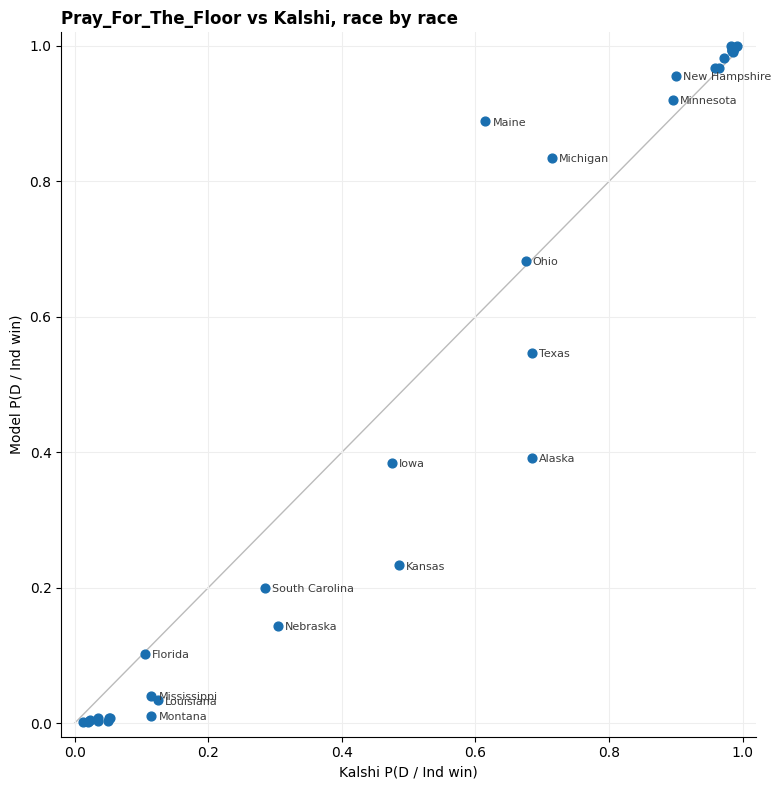

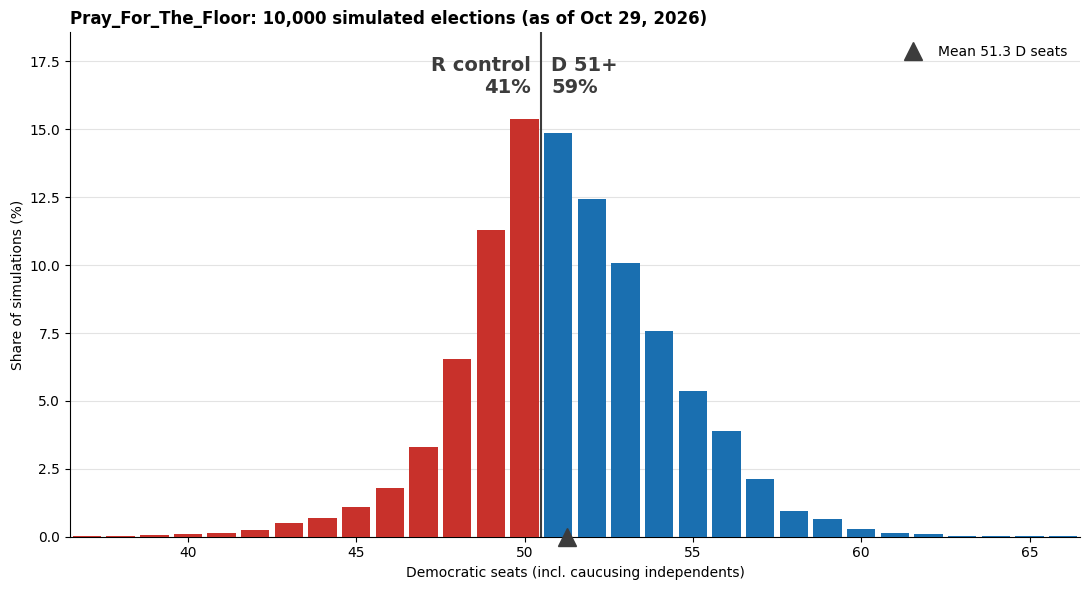

Saved race_probabilities.csv, state_win_probabilities.csv, polls_used.csv, national_signals.csv, seat_distribution.csv/.png, model_vs_kalshi.png, config_snapshot.json, headline.json to C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast\Models\Pray_For_The_Floor\Output
Standard export -> C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast\Models\Pray_For_The_Floor\Output\standard


In [1]:
%run ./pray_for_the_floor.ipynb

In [2]:
TEST_DIR = CONFIG["OUT_DIR"] / "testing"
TEST_DIR.mkdir(parents=True, exist_ok=True)
CHECKS = []


def check(section, name, status, detail):
    """Record one check. status: PASS / WARN / FAIL."""
    CHECKS.append({"section": section, "check": name, "status": status, "detail": detail})


COLORS = {"PASS": "background-color:#DFF0D8", "WARN": "background-color:#FCF8E3", "FAIL": "background-color:#F2DEDE"}


def show(section):
    t = pd.DataFrame([c for c in CHECKS if c["section"] == section])
    if not len(t):
        return
    try:
        display(t.drop(columns="section").style.map(lambda v: COLORS.get(v, ""), subset=["status"]))
    except (AttributeError, ImportError):
        display(t.drop(columns="section"))


def show_df(df, fmt=None):
    try:
        display(df.style.format(fmt or {}))
    except (AttributeError, ImportError):
        display(df.round(3))


SIM_N = 3000  # simulations per re-run in sections E and F (fewer than the main run, for speed)
r, polls, env, today = RES["races"], RES["polls"], RES["env"], RES["today"]

## A. Data checks
- **Sources:** each download should say *live*. *cache* means the website was unreachable and the last saved copy was used.
- **Freshness:** the newest state poll should be under 7 days old and the newest national poll under 21 days.
- **Kalshi search vs the fallback table:** any race where the search found a *different* market, or fell back to the table, is listed.
- **Nominees:** taken from Kalshi's candidate names; disagreements with the fallback table are listed.
- **Ungraded pollsters:** what share of the poll weight rests on firms VoteHub hasn't graded (these get random grades).

In [3]:
for name, stat in SOURCE_STATUS.items():
    check("A", f"source: {name}", "PASS" if stat == "live" else "WARN", stat)

newest = DATA["senate"]["end_date"].max()
age = (today - newest).days
check("A", "newest state poll", "PASS" if age <= 7 else "WARN", f"{newest:%Y-%m-%d} ({age} days old)")
for nm, df in [("generic ballot", DATA["generic"]), ("approval", DATA["approval"])]:
    d = df.loc[df["Date"] <= today, "Date"].max()
    a = (today - d).days
    check("A", f"newest {nm} poll (VoteHub)", "PASS" if a <= 21 else "WARN",
          f"{d:%Y-%m-%d} ({a} days old){' - Kalshi averages fill the gap' if a > 21 else ''}")
fk = DATA["kalshi_races"]["fetched"].iloc[0] if "fetched" in DATA["kalshi_races"] else "?"
check("A", "Kalshi race prices date", "PASS" if str(fk) == pd.Timestamp.today().strftime("%Y-%m-%d") else "WARN", f"fetched {fk}")

kc = KALSHI_CHECK
missing = kc.index[kc["found_event"].isna()].tolist()
check("A", "Kalshi races found", "PASS" if not missing else "FAIL", f"{kc['found_event'].notna().sum()}/35" + (f"; missing {missing}" if missing else ""))
fb = kc.index[kc["found_by"] == "fallback table"].tolist()
check("A", "Kalshi races found by title search", "PASS" if not fb else "WARN", "all" if not fb else f"used the fallback table for {fb}")
diff = kc[~kc["matches_fallback_table"] & kc["found_event"].notna()]
check("A", "Kalshi search agrees with fallback table", "PASS" if diff.empty else "WARN",
      "all agree" if diff.empty else "; ".join(f"{st}: found {a}, table {b}" for st, (a, b) in diff[["found_event", "fallback_table"]].iterrows()))
nd = NOMINEE_CHECK[~NOMINEE_CHECK["matches_fallback_table"]]
check("A", "nominees agree with fallback table", "PASS" if nd.empty else "WARN",
      "all 35 agree" if nd.empty else "; ".join(f"{st}: {row['republican']} vs {row['opposition']}" for st, row in nd.iterrows()))
part = NOMINEE_CHECK.index[NOMINEE_CHECK["source"] != "Kalshi"].tolist()
check("A", "nominees from Kalshi names", "PASS" if len(part) <= 1 else "WARN",
      f"{35 - len(part)}/35 from Kalshi; fallback table used for {part}")
check("A", "polls dropped for missing nominees", "PASS" if N_UNMATCHED <= 0.2 * max(len(DATA["senate"]), 1) else "WARN",
      f"{N_UNMATCHED} of {len(DATA['senate'])} VoteHub rows (old hypothetical match-ups)")
if len(polls):
    sh = polls.loc[polls["Unrated"], "weight"].sum() / polls["weight"].sum()
    check("A", "weight from ungraded pollsters", "PASS" if sh < 0.5 else "WARN",
          f"{polls['Unrated'].sum()} of {len(polls)} polls, {sh:.0%} of poll weight ({CONFIG['UNRATED_POLLSTERS']} grades)")
for sig, row in env["table"].iterrows():
    check("A", f"national: {sig}", "PASS" if row["effective n"] >= 3 or row["Kalshi counts as"] > 0 else "WARN",
          f"{row['n polls']:.0f} VoteHub polls (effective {row['effective n']:.1f}) + Kalshi counted as {row['Kalshi counts as']:.0f} -> {row['combined']:+.1f}")
check("A", "undecided share U used for Kalshi approval", "PASS" if 0 <= env["U"] <= 10 else "WARN", f"U = {env['U']:.1f} pts")
if CONFIG["SCORECARD_HOUSE_EFFECTS"] and CONFIG["ESTIMATE_HOUSE_EFFECTS"]:
    check("A", "house effects corrected twice", "WARN", "SCORECARD_HOUSE_EFFECTS and ESTIMATE_HOUSE_EFFECTS are both on")
show("A")

,check,status,detail
0,source: votehub_senate_cache.csv,PASS,live
1,source: votehub_generic_ballot_cache.csv,PASS,live
2,source: votehub_approval_cache.csv,PASS,live
3,source: kalshi_races_cache.csv,PASS,live
4,source: kalshi_national_cache.csv,PASS,live
5,newest state poll,PASS,2026-10-27 (2 days old)
6,newest generic ballot poll (VoteHub),WARN,2026-10-04 (25 days old) - Kalshi averages fill the gap
7,newest approval poll (VoteHub),WARN,2026-10-06 (23 days old) - Kalshi averages fill the gap
8,Kalshi race prices date,PASS,fetched 2026-10-29
9,Kalshi races found,PASS,35/35


## B. Model sanity checks
Internal consistency: these should always PASS. A FAIL means a bug, not a data problem.

In [4]:
p_ok = r["p_dem"].between(0, 1).all() and r["kalshi_p"].dropna().between(0, 1).all()
check("B", "probabilities between 0 and 1", "PASS" if p_ok else "FAIL", "race and Kalshi probabilities")
shares = (r["share_prior"] + r["share_polls"] + r["share_kalshi"] - 1).abs().max()
check("B", "source shares add to 100%", "PASS" if shares < 1e-9 else "FAIL", f"max error {shares:.1e}")
check("B", "no missing race margins", "PASS" if r["post_mean"].notna().all() and r["post_sd"].gt(0).all() else "FAIL", "post_mean / post_sd")
ds = RES["d_seats"]
lo_, hi_ = CONFIG["HOLDOVER_D"] - len(CONFIG["HOLDOVER_DEFECTION_PROB"]), CONFIG["HOLDOVER_D"] + 35
check("B", "seat counts possible", "PASS" if ds.min() >= lo_ and ds.max() <= hi_ else "FAIL", f"range {ds.min()}-{ds.max()} (possible {lo_}-{hi_})")
exp_from_races = CONFIG["HOLDOVER_D"] + sum(pv * CONFIG["INDEPENDENT_CAUCUS_PROB_D"].get(st, 1.0) for st, pv in r["p_dem"].items())
gap = abs(exp_from_races - RES["summary"]["exp_d_seats"])
check("B", "mean seats = sum of race probabilities", "PASS" if gap < 0.15 else "WARN", f"{RES['summary']['exp_d_seats']:.2f} vs {exp_from_races:.2f}")
sim_gap = (r["p_dem_state_sim"] - r["p_dem_national_sim"]).abs().max()
check("B", "independent vs correlated simulations agree", "PASS" if sim_gap < 0.03 else "WARN", f"largest race gap {sim_gap:.1%}")
pv = RES["summary"]["p_d_51"]
se = np.sqrt(pv * (1 - pv) / CONFIG["N_SIMS"])
check("B", "simulation noise on P(51+)", "PASS" if se < 0.01 else "WARN", f"±{1.96 * se:.1%} (95% range) with {CONFIG['N_SIMS']:,} simulations")
kk = r["share_kalshi"]
check("B", "Kalshi share of the final margin", "PASS" if kk.max() <= 0.35 else "WARN",
      f"median {kk.median():.0%}, max {kk.max():.0%} ({kk.idxmax()})" if kalshi_on(CONFIG) else "Kalshi off")
show("B")

,check,status,detail
0,probabilities between 0 and 1,PASS,race and Kalshi probabilities
1,source shares add to 100%,PASS,max error 2.2e-16
2,no missing race margins,PASS,post_mean / post_sd
3,seat counts possible,PASS,range 35-69 (possible 33-69)
4,mean seats = sum of race probabilities,PASS,51.26 vs 51.26
5,independent vs correlated simulations agree,PASS,largest race gap 0.6%
6,simulation noise on P(51+),PASS,"±1.0% (95% range) with 10,000 simulations"
7,Kalshi share of the final margin,PASS,"median 7%, max 16% (Colorado)"


## C. Coverage by race
**WARN** = a race Kalshi gives between 15% and 85% (so it could matter for control) with fewer than 3 effective polls or a newest poll over 14 days old.

In [5]:
cov = pd.DataFrame({"n_polls": r["n_polls"], "effective n": r["n_eff"].round(1), "newest poll (days)": r["last_poll_age"],
                    "share from polls": r["share_polls"].round(2), "share from prior": r["share_prior"].round(2),
                    "model P": r["p_dem"].round(2), "Kalshi P": r["kalshi_p"].round(2)})
contested = cov["Kalshi P"].between(0.15, 0.85)
thin = contested & ((cov["effective n"] < 3) | (cov["newest poll (days)"].fillna(999) > 14))
cov["flag"] = np.where(thin, "thin + contested", "")
for st in cov.index[thin]:
    check("C", f"coverage: {st}", "WARN", f"{cov.loc[st, 'n_polls']} polls (effective {cov.loc[st, 'effective n']}), Kalshi {cov.loc[st, 'Kalshi P']:.0%}")
if not thin.any():
    check("C", "coverage of contested races", "PASS", "every race Kalshi rates 15-85% has 3+ effective recent polls")
display(cov.sort_values("Kalshi P", ascending=False))
cov.to_csv(TEST_DIR / "coverage.csv")
show("C")

,n_polls,effective n,newest poll (days),share from polls,share from prior,model P,Kalshi P,flag
State,,,,,,,,
Rhode Island,4,1.8,21.0,0.59,0.34,1.00,0.99,
Oregon,0,0.0,NaN,0.00,0.84,1.00,0.99,
Colorado,0,0.0,NaN,0.00,0.84,0.99,0.98,
New Mexico,2,1.9,29.0,0.54,0.39,0.99,0.98,
Virginia,2,2.0,135.0,0.57,0.36,0.99,0.98,
Illinois,2,1.9,9.0,0.58,0.35,0.99,0.98,
Delaware,0,0.0,NaN,0.00,0.84,1.00,0.98,
Massachusetts,12,4.3,12.0,0.61,0.33,1.00,0.98,
New Jersey,0,0.0,NaN,0.00,0.84,0.98,0.97,


,check,status,detail
0,coverage: Kansas,WARN,"4 polls (effective 1.8), Kalshi 48%"
1,coverage: South Carolina,WARN,"3 polls (effective 2.3), Kalshi 29%"


## D. Disagreements with Kalshi
Races where the model and Kalshi differ by more than 25 points. These aren't errors; they're the races worth discussing (candidate quality, late events, or polls the market doesn't believe).

In [6]:
dis = pd.DataFrame({"model P": r["p_dem"], "Kalshi P": r["kalshi_p"], "gap": r["p_dem"] - r["kalshi_p"],
                    "prior": r["prior_mean"].map(margin_label), "polls": r["poll_mean"].map(margin_label),
                    "final": r["post_mean"].map(margin_label)})
big = dis[dis["gap"].abs() > 0.25].sort_values("gap")
for st, row in big.iterrows():
    check("D", f"model vs Kalshi: {st}", "WARN", f"model {row['model P']:.0%} vs Kalshi {row['Kalshi P']:.0%} (prior {row['prior']}, polls {row['polls']})")
if big.empty:
    check("D", "model vs Kalshi", "PASS", "no race differs by more than 25 points")
show_df(big, {"model P": "{:.0%}", "Kalshi P": "{:.0%}", "gap": "{:+.0%}"}) if len(big) else print("No large disagreements.")
show("D")

,model P,Kalshi P,gap,prior,polls,final
State,,,,,,
Alaska,39%,68%,-29%,R+6.5,D+1.0,R+1.0
Kansas,23%,48%,-25%,R+10.5,D+0.4,R+3.2
Maine,89%,62%,+27%,D+13.5,D+2.0,D+5.1


,check,status,detail
0,model vs Kalshi: Alaska,WARN,"model 39% vs Kalshi 68% (prior R+6.5, polls D+1.0)"
1,model vs Kalshi: Kansas,WARN,"model 23% vs Kalshi 48% (prior R+10.5, polls D+0.4)"
2,model vs Kalshi: Maine,WARN,"model 89% vs Kalshi 62% (prior D+13.5, polls D+2.0)"


## E. Robustness

### E1. Sensitivity sweep
Changes **one setting at a time** (everything else stays at its CONFIG value) and re-runs with 3,000 simulations and the same random seed, so differences come from the setting rather than simulation noise. Model 1's sweep list plus the new settings. Longer bars = settings the answer depends on more. Edit `SWEEP_PARAMS` to test other values.

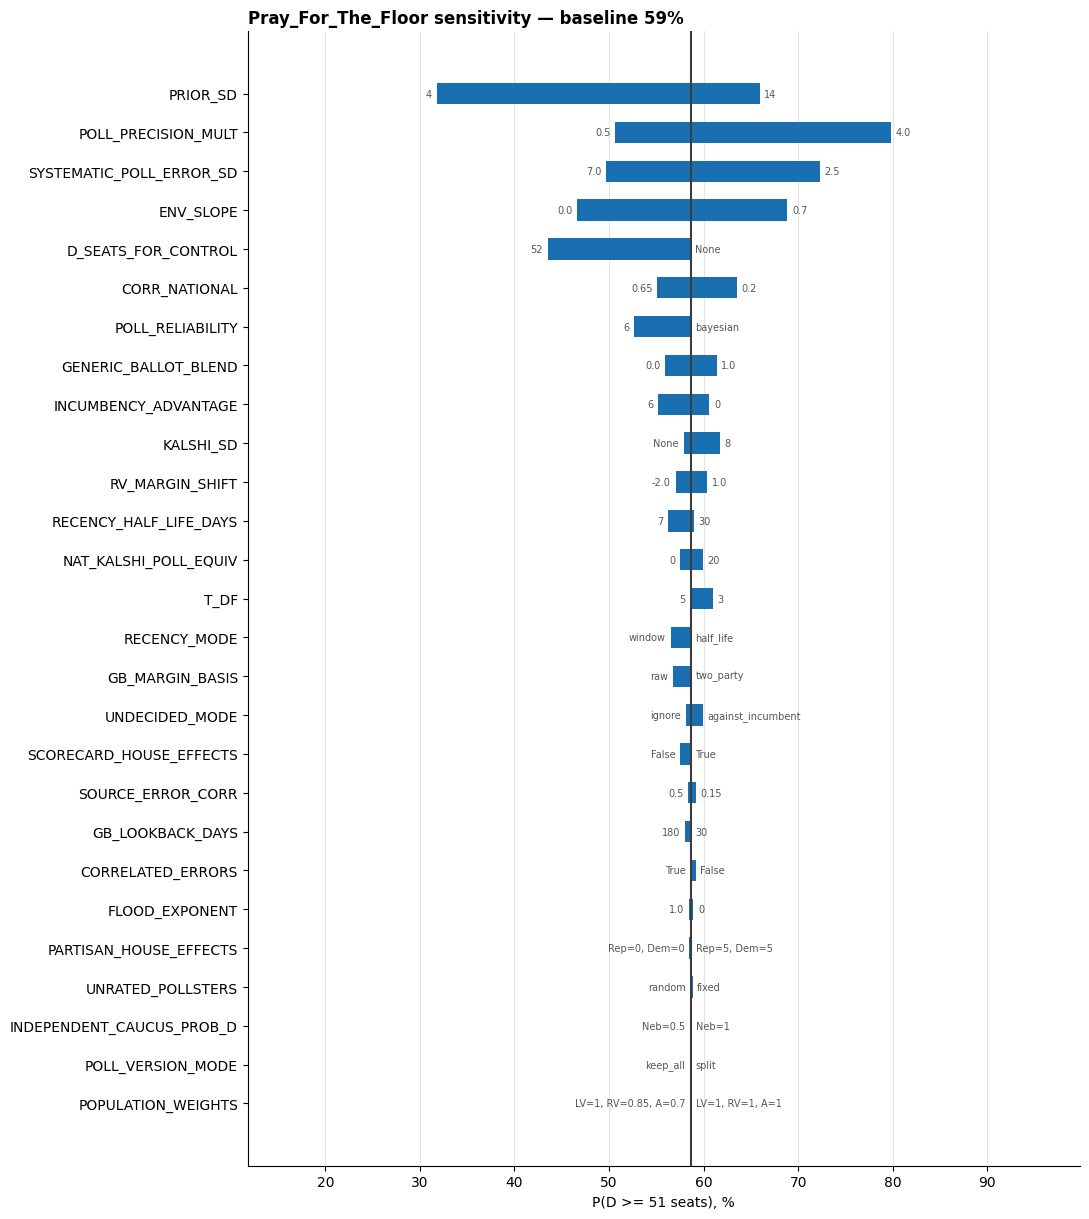

In [7]:
SWEEP_PARAMS = {
    # Model 1's sweep
    "RECENCY_HALF_LIFE_DAYS": [7, 14, 21, 30, 45],
    "ENV_SLOPE": [0.0, 0.2, 0.35, 0.5, 0.7],
    "GENERIC_BALLOT_BLEND": [0.0, 0.25, 0.5, 0.75, 1.0],
    "GB_MARGIN_BASIS": ["raw", "two_party"],
    "GB_LOOKBACK_DAYS": [30, 60, 90, 180],
    "PRIOR_SD": [4, 6, 7.5, 10, 14],
    "POLL_PRECISION_MULT": [0.5, 1.0, 2.0, 4.0],
    "SYSTEMATIC_POLL_ERROR_SD": [2.5, 3.5, 4.5, 5.5, 7.0],
    "PARTISAN_HOUSE_EFFECTS": [{"Republican": h, "Democrat": h} for h in (0, 1.5, 3, 5)],
    "RV_MARGIN_SHIFT": [-2.0, -1.0, -0.5, 0.0, 1.0],
    "INCUMBENCY_ADVANTAGE": [0, 1, 2, 3, 4, 6],
    "UNDECIDED_MODE": ["ignore", "proportional", "against_incumbent"],
    "POLL_VERSION_MODE": ["keep_all", "split", "prefer_h2h", "prefer_full_field"],
    "CORR_NATIONAL": [0.2, 0.35, 0.45, 0.55, 0.65],
    "T_DF": [3, 5, 10, 30],
    "INDEPENDENT_CAUCUS_PROB_D": [{"Nebraska": p} for p in (0.5, 0.8, 1.0)],
    "D_SEATS_FOR_CONTROL": [None, 52],
    # New in Pray_For_The_Floor
    "KALSHI_SD": [None, 8, 12, 17, 25],
    "POLL_RELIABILITY": ["bayesian", 1, 3, 6],
    "RECENCY_MODE": ["half_life", "window"],
    "POPULATION_WEIGHTS": [{"LV": 1.0, "RV": 0.85, "A": 0.7}, {"LV": 1.0, "RV": 0.9, "A": 0.8}, {"LV": 1.0, "RV": 1.0, "A": 1.0}],
    "UNRATED_POLLSTERS": ["fixed", "random"],
    "SCORECARD_HOUSE_EFFECTS": [False, True],
    "NAT_KALSHI_POLL_EQUIV": [0, 2, 5, 10, 20],
    "FLOOD_EXPONENT": [0, 0.5, 1.0],
    "CORRELATED_ERRORS": [False, True],
    "SOURCE_ERROR_CORR": [0.0, 0.15, 0.3, 0.5],
}
SWEEP_TRACK_STATES = ["Maine", "North Carolina", "Ohio", "Texas", "Iowa", "Alaska", "Michigan", "Nebraska"]


def value_label(v):
    if v is None:
        return "None"
    if isinstance(v, dict):
        return ", ".join(f"{k.split('/')[0][:3]}={x:g}" for k, x in v.items())
    return str(v)


base = run_model(DATA, CONFIG, n_sims=SIM_N, verbose=False)["summary"]
rows = []
for key, values in SWEEP_PARAMS.items():
    for v in values:
        res = run_model(DATA, {**copy.deepcopy(CONFIG), key: v}, n_sims=SIM_N, verbose=False)
        rows.append({"param": key, "value": value_label(v), "is_default": v == CONFIG[key], "p_d_51": res["summary"]["p_d_51"],
                     "exp_d_seats": res["summary"]["exp_d_seats"],
                     **{f"P(D) {st}": res["races"].loc[st, "p_dem"] for st in SWEEP_TRACK_STATES}})
sweep = pd.DataFrame(rows)
sweep.to_csv(TEST_DIR / "sensitivity_sweep.csv", index=False)

rng_ = sweep.groupby("param")["p_d_51"].agg(["min", "max"])
lo = sweep.loc[sweep.groupby("param")["p_d_51"].idxmin()].set_index("param")["value"]
hi = sweep.loc[sweep.groupby("param")["p_d_51"].idxmax()].set_index("param")["value"]
rng_ = rng_.assign(span=rng_["max"] - rng_["min"]).sort_values("span")
fig, ax = plt.subplots(figsize=(11, 0.4 * len(rng_) + 1.5))
y = np.arange(len(rng_))
ax.barh(y, 100 * rng_["span"], left=100 * rng_["min"], height=0.55, color="#1A6FB0", zorder=3)
ax.axvline(100 * base["p_d_51"], color="#3C3C3C", lw=1.5, zorder=4)
for i, (prm, rr) in enumerate(rng_.iterrows()):
    ax.text(100 * rr["min"] - 0.5, i, lo[prm], ha="right", va="center", fontsize=7, color="#555555")
    ax.text(100 * rr["max"] + 0.5, i, hi[prm], ha="left", va="center", fontsize=7, color="#555555")
ax.set_yticks(y, rng_.index)
ax.set_xlabel("P(D >= 51 seats), %")
ax.grid(axis="x", color="#E3E3E3", zorder=0)
ax.spines[["right", "top"]].set_visible(False)
ax.set_title(f"Pray_For_The_Floor sensitivity — baseline {base['p_d_51']:.0%}", loc="left", fontweight="bold")
ax.set_xlim(max(0, 100 * rng_["min"].min() - 20), min(100, 100 * rng_["max"].max() + 20))
fig.tight_layout()
fig.savefig(TEST_DIR / "sensitivity_tornado.png", dpi=200, bbox_inches="tight")
plt.show()
top = rng_.sort_values("span", ascending=False).head(3)
check("E", "most influential settings", "PASS", "; ".join(f"{k}: {v['min']:.0%}-{v['max']:.0%}" for k, v in top.iterrows()))

### E2. Which races are most assumption-sensitive?
For each setting, the spread (max − min) of each tracked state's P(D win) across the values tried (Model 1's table). Large numbers flag races where the team's choices matter most.

In [8]:
state_cols = [c for c in sweep.columns if c.startswith("P(D) ")]
spread = sweep.groupby("param")[state_cols].agg(lambda x: x.max() - x.min())
spread.columns = [c.replace("P(D) ", "") for c in state_cols]
spread.to_csv(TEST_DIR / "state_sensitivity.csv")
try:
    display(spread.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None))
except (AttributeError, ImportError):
    display(spread.round(2))

,Maine,North Carolina,Ohio,Texas,Iowa,Alaska,Michigan,Nebraska
param,,,,,,,,
CORRELATED_ERRORS,3%,1%,3%,1%,2%,3%,4%,3%
CORR_NATIONAL,0%,0%,1%,1%,2%,0%,0%,0%
D_SEATS_FOR_CONTROL,0%,0%,0%,0%,0%,0%,0%,0%
ENV_SLOPE,7%,2%,17%,18%,18%,19%,10%,6%
FLOOD_EXPONENT,0%,0%,0%,1%,3%,1%,1%,1%
GB_LOOKBACK_DAYS,0%,0%,1%,1%,1%,1%,0%,0%
GB_MARGIN_BASIS,1%,0%,2%,1%,1%,2%,1%,1%
GENERIC_BALLOT_BLEND,2%,1%,4%,4%,4%,4%,2%,1%
INCUMBENCY_ADVANTAGE,7%,0%,0%,0%,0%,17%,0%,5%


### E3. The two on/off toggles
`SCORECARD_HOUSE_EFFECTS` changes each poll's *margin*; `CORRELATED_ERRORS` changes each race's *uncertainty*. They're independent, so all four combinations are valid.

In [9]:
rows = []
for he in (False, True):
    for ce in (False, True):
        res = run_model(DATA, {**CONFIG, "SCORECARD_HOUSE_EFFECTS": he, "CORRELATED_ERRORS": ce}, n_sims=SIM_N, verbose=False)
        comp = res["races"]
        rows.append({"SCORECARD_HOUSE_EFFECTS": he, "CORRELATED_ERRORS": ce, "P(D >= 51)": res["summary"]["p_d_51"],
                     "D seats": res["summary"]["exp_d_seats"], "avg race sd": comp["post_sd"].mean(),
                     "P(D) Maine": comp.loc["Maine", "p_dem"], "P(D) Texas": comp.loc["Texas", "p_dem"]})
toggles = pd.DataFrame(rows)
toggles.to_csv(TEST_DIR / "toggles.csv", index=False)
show_df(toggles, {"P(D >= 51)": "{:.1%}", "D seats": "{:.1f}", "avg race sd": "{:.2f}", "P(D) Maine": "{:.0%}", "P(D) Texas": "{:.0%}"})
spread_t = toggles["P(D >= 51)"].max() - toggles["P(D >= 51)"].min()
check("E", "toggle combinations agree", "PASS" if spread_t < 0.05 else "WARN", f"P(51+) spread {spread_t:.1%} across the 4 combinations")

,SCORECARD_HOUSE_EFFECTS,CORRELATED_ERRORS,P(D >= 51),D seats,avg race sd,P(D) Maine,P(D) Texas
0,False,False,58.0%,51.2,5.00,94%,53%
1,False,True,57.5%,51.2,5.86,90%,53%
2,True,False,59.2%,51.2,5.00,93%,55%
3,True,True,58.6%,51.3,5.86,90%,54%


### E4. Random grades: how much do they matter?
Compares `UNRATED_POLLSTERS = "random"` (redrawn in every simulation) with Model 1's `"fixed"` lowest grade, at the full number of simulations.

In [10]:
res_fixed = run_model(DATA, {**CONFIG, "UNRATED_POLLSTERS": "fixed"}, verbose=False)
cmp = pd.DataFrame({"random (this run)": r["p_dem"], "fixed (Model 1)": res_fixed["races"]["p_dem"]})
cmp["difference"] = cmp["random (this run)"] - cmp["fixed (Model 1)"]
cmp = cmp[cmp["difference"].abs() > 0.005].sort_values("difference")
print(f"P(D >= 51): random {RES['summary']['p_d_51']:.1%} vs fixed {res_fixed['summary']['p_d_51']:.1%}")
show_df(cmp, {c: "{:.1%}" for c in cmp.columns}) if len(cmp) else print("No race moves by more than half a point.")
check("E", "random vs fixed grades", "PASS", f"P(51+) {RES['summary']['p_d_51']:.1%} vs {res_fixed['summary']['p_d_51']:.1%}; "
      f"{len(cmp)} races move by more than 0.5 pts")

P(D >= 51): random 58.7% vs fixed 57.9%


,random (this run),fixed (Model 1),difference
State,,,
Alaska,39.2%,43.4%,-4.2%
Kansas,23.3%,22.7%,0.6%
Michigan,83.5%,82.8%,0.7%
South Carolina,19.9%,18.9%,1.0%
Ohio,68.3%,67.1%,1.2%
Texas,54.7%,51.4%,3.3%


### E5. Simulation noise and random seeds
Re-runs the full model with 5 different random seeds. If P(51+) jumps by more than a point or two, raise `N_SIMS`.

In [11]:
seed_rows = []
for sd in [CONFIG["SEED"], 1, 7, 42, 99]:
    res = run_model(DATA, {**CONFIG, "SEED": sd}, verbose=False)["summary"]
    seed_rows.append({"seed": sd, "P(D >= 51)": res["p_d_51"], "D seats": res["exp_d_seats"]})
seeds = pd.DataFrame(seed_rows)
show_df(seeds, {"P(D >= 51)": "{:.1%}", "D seats": "{:.2f}"})
rg = seeds["P(D >= 51)"].max() - seeds["P(D >= 51)"].min()
check("E", "stable across random seeds", "PASS" if rg < 0.02 else "WARN", f"P(51+) range {rg:.1%} over 5 seeds at {CONFIG['N_SIMS']:,} simulations")
show("E")

,seed,P(D >= 51),D seats
0,2026,58.7%,51.26
1,1,60.1%,51.34
2,7,58.7%,51.26
3,42,60.2%,51.36
4,99,58.8%,51.26


,check,status,detail
0,most influential settings,PASS,PRIOR_SD: 32%-66%; POLL_PRECISION_MULT: 51%-80%; SYSTEMATIC_POLL_ERROR_SD: 50%-72%
1,toggle combinations agree,PASS,P(51+) spread 1.7% across the 4 combinations
2,random vs fixed grades,PASS,P(51+) 58.7% vs 57.9%; 6 races move by more than 0.5 pts
3,stable across random seeds,PASS,"P(51+) range 1.5% over 5 seeds at 10,000 simulations"


## F. Trajectory: the forecast week by week
Re-runs the model **as of** each Monday since September 7 (backtests). Each run uses only polls *released* by that date and **that day's Kalshi race prices**; the national numbers use polls only. The dashed line is Kalshi's own P(Democrats win the Senate) on the same dates.

*Note:* the first time this runs, it downloads Kalshi's daily price history (one request per market, ~30 seconds) and saves it to `Data_Cache/`.

kalshi_history_cache.csv: API unavailable (HTTPError); using saved copy with 105 rows


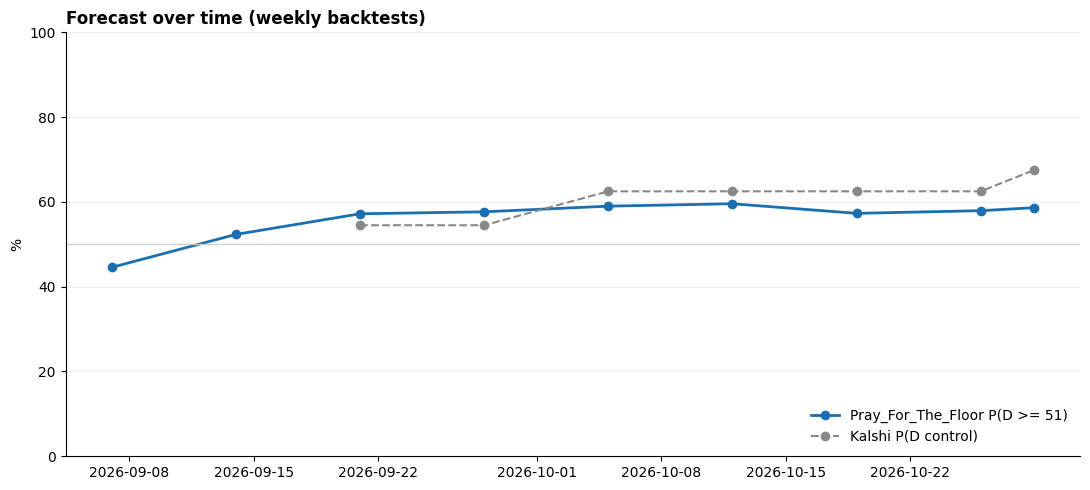

,P(D >= 51),D seats,Kalshi P(control),polls used
date,,,,
2026-09-07 00:00:00,44.6%,50.1,nan%,194
2026-09-14 00:00:00,52.3%,50.7,nan%,208
2026-09-21 00:00:00,57.2%,50.9,54.5%,224
2026-09-28 00:00:00,57.7%,51.0,54.5%,243
2026-10-05 00:00:00,59.0%,51.1,62.5%,263
2026-10-12 00:00:00,59.6%,51.4,62.5%,285
2026-10-19 00:00:00,57.3%,51.1,62.5%,304
2026-10-26 00:00:00,57.9%,51.1,62.5%,344
2026-10-29 00:00:00,58.6%,51.3,67.5%,358


,check,status,detail
0,week-to-week stability,PASS,largest weekly move 8%


In [12]:
dates = list(pd.date_range("2026-09-07", today - pd.Timedelta(days=1), freq="W-MON")) + [today]
traj = []
for d in dates:
    try:
        res = run_model(DATA, {**CONFIG, "AS_OF_DATE": None if d == today else d.strftime("%Y-%m-%d")}, n_sims=SIM_N, verbose=False)
    except Exception as e:  # e.g. no Kalshi history available offline
        print(f"{d:%Y-%m-%d}: skipped ({type(e).__name__}: {e})")
        continue
    kt_ = res["kalshi"]
    traj.append({"date": d, "P(D >= 51)": res["summary"]["p_d_51"], "D seats": res["summary"]["exp_d_seats"],
                 "Kalshi P(control)": float(kt_.loc["CONTROL", "p_opp"]) if "CONTROL" in kt_.index else np.nan,
                 "polls used": len(res["polls"])})
traj = pd.DataFrame(traj).set_index("date")
traj.to_csv(TEST_DIR / "trajectory.csv")
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(traj.index, 100 * traj["P(D >= 51)"], marker="o", color="#1A6FB0", lw=2, label="Pray_For_The_Floor P(D >= 51)")
ax.plot(traj.index, 100 * traj["Kalshi P(control)"], marker="o", color="#888888", lw=1.5, ls="--", label="Kalshi P(D control)")
ax.axhline(50, color="#CCCCCC", lw=1)
ax.set_ylim(0, 100)
ax.set_ylabel("%")
ax.grid(axis="y", color="#EEEEEE")
ax.spines[["right", "top"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Forecast over time (weekly backtests)", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(TEST_DIR / "trajectory.png", dpi=200, bbox_inches="tight")
plt.show()
show_df(traj, {"P(D >= 51)": "{:.1%}", "D seats": "{:.1f}", "Kalshi P(control)": "{:.1%}"})
jump = traj["P(D >= 51)"].diff().abs().max() if len(traj) > 1 else 0.0
check("F", "week-to-week stability", "PASS" if jump < 0.15 else "WARN", f"largest weekly move {jump:.0%}")
show("F")

## G. Summary of every check
Saved to `Output/testing/checks.csv` (also read by `run_all.py`). Before publishing a run, make sure there are no FAILs and that you understand every WARN.

In [13]:
summary = pd.DataFrame(CHECKS)
summary.to_csv(TEST_DIR / "checks.csv", index=False)
counts = summary["status"].value_counts()
print(f"{counts.get('PASS', 0)} PASS | {counts.get('WARN', 0)} WARN | {counts.get('FAIL', 0)} FAIL")
try:
    display(summary.style.map(lambda v: COLORS.get(v, ""), subset=["status"]))
except (AttributeError, ImportError):
    display(summary)

28 PASS | 9 WARN | 0 FAIL


,section,check,status,detail
0,A,source: votehub_senate_cache.csv,PASS,live
1,A,source: votehub_generic_ballot_cache.csv,PASS,live
2,A,source: votehub_approval_cache.csv,PASS,live
3,A,source: kalshi_races_cache.csv,PASS,live
4,A,source: kalshi_national_cache.csv,PASS,live
5,A,newest state poll,PASS,2026-10-27 (2 days old)
6,A,newest generic ballot poll (VoteHub),WARN,2026-10-04 (25 days old) - Kalshi averages fill the gap
7,A,newest approval poll (VoteHub),WARN,2026-10-06 (23 days old) - Kalshi averages fill the gap
8,A,Kalshi race prices date,PASS,fetched 2026-10-29
9,A,Kalshi races found,PASS,35/35
